# Python for AI Development
## AIAT 111 - Unit 1: Introduction to AI and Applications

---

## 📚 Learning Objectives

By completing this notebook, you will:
- Review Python basics essential for AI development
- Work with lists, dictionaries, loops, and conditionals
- Use NumPy for matrix operations
- Read and write files in Python
- Prepare Python code for AI applications

---

## 🔗 Where this fits

**Builds on:** Unit 1, lesson 01 "AI Introduction" — the vocabulary; this lesson sets up the NumPy/file-handling tooling every later notebook uses.

**Used later in:** Course 05 (AIAT 115) — Unit 1, where the same NumPy array thinking is scaled to full DataFrames.

---


## 🎯 Why an array library earns a whole lesson

`import numpy as np` looks like housekeeping. It is not. When the NumPy team
finally described their library in *Nature* in 2020, they justified it with two
specific results: NumPy "was an important part of the software stack used in the
discovery of gravitational waves and the first imaging of a black hole" (Harris
et al., 2020 — reference 1 at the foot of this notebook). The LIGO detection
announced in 2016 and the Event Horizon Telescope image released in 2019 were,
at the level of code, enormous numbers of operations on arrays of numbers.

Nothing in this notebook is conceptually harder than what those pipelines do.
They are the same four moves: put numbers in an array, give the array a shape,
apply an operation to the whole array at once, and read results back from a file.

### What goes wrong without arrays

A Python list stores a pointer to a separate Python object per element, and a
`for` loop pays a fresh interpreter step per item. A NumPy array stores one
contiguous block of raw numbers and hands the loop to compiled C. On the
five-element toy below the difference is invisible — which is exactly the trap.
On the arrays a real model touches (one 224×224 colour image is already 150,528
numbers, and a training batch is 32 of those) the list version is not "slower",
it is unusable. Every later notebook in this diploma assumes you reached for the array.


## 1. Python Basics Review

Essential Python concepts for AI development:


In [1]:
# Lists - Essential for data manipulation
data_points = [1, 2, 3, 4, 5]
print(f"Data points: {data_points}")
print(f"Sum: {sum(data_points)}")
print(f"Average: {sum(data_points) / len(data_points)}")


Data points: [1, 2, 3, 4, 5]
Sum: 15
Average: 3.0


In [2]:
# Dictionaries hold labeled facts about one entity — the shape most datasets take
# before they become tables, so being fluent with them pays off in every ML notebook.
# Dictionaries - For structured data
student_data = {
    'name': 'Ahmed',
    'age': 22,
    'courses': ['AI', 'ML', 'NLP'],
    'grades': {'AI': 95, 'ML': 88, 'NLP': 92}
}

# Read single fields out, then aggregate across the nested grades dict — a mini data-analysis step.
print(f"Student: {student_data['name']}")
print(f"Average grade: {sum(student_data['grades'].values()) / len(student_data['grades'])}")

Student: Ahmed
Average grade: 91.66666666666667


In [3]:
# Loops and comprehensions are how we process whole datasets one record at a time;
# here we compute an average manually before NumPy does it for us later.
# Loops - For processing data
scores = [85, 90, 78, 92, 88]
total = 0
for score in scores:
    total += score
    
average = total / len(scores)
print(f"Average score: {average}")

# List comprehension (Pythonic way)
squared = [x**2 for x in range(1, 6)]
print(f"Squared numbers: {squared}")

Average score: 86.6
Squared numbers: [1, 4, 9, 16, 25]


## 2. NumPy for Matrix Operations

NumPy is essential for AI as it provides efficient numerical operations:


In [4]:
# NumPy arrays are the core data structure of AI: every image, dataset, and model
# weight you will meet later is stored as an n-dimensional array like these.
import numpy as np

# Creating arrays
vector = np.array([1, 2, 3, 4, 5])
matrix = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])

# Shape tells you the dimensions — the first thing to check when debugging any ML code.
print(f"Vector: {vector}")
print(f"Matrix shape: {matrix.shape}")
print(f"\nMatrix:\n{matrix}")

Vector: [1 2 3 4 5]
Matrix shape: (3, 3)

Matrix:
[[1 2 3]
 [4 5 6]
 [7 8 9]]


In [5]:
# Matrix operations - Essential for AI

# Matrix multiplication
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

result = np.dot(A, B)
print(f"Matrix A:\n{A}")
print(f"\nMatrix B:\n{B}")
print(f"\nA × B:\n{result}")


Matrix A:
[[1 2]
 [3 4]]

Matrix B:
[[5 6]
 [7 8]]

A × B:
[[19 22]
 [43 50]]


## ✏️ Your turn: same arithmetic, whole-array style

The loop cell computed the average of `scores` one element at a time; the NumPy cells built
`matrix` and multiplied two small matrices. Now do the loop's job *and* three whole-array
operations yourself, on the same objects, before the next cell times exactly this difference.

1. **Predict by hand first.** `matrix` is 3 × 3 and `weights = [1, 2, 3]` has 3 entries.
   What shape does `matrix @ weights` have, and what is its **first** number
   (row 1 of `matrix` times `weights`, added up)? Write both down.
2. Set `scores_mean` with NumPy (`np.mean` on `scores_array`) - it must equal the loop's
   `average` above. Expected: one number.
3. Set `row_sums`: the sum of each **row** of `matrix` (one number per row - 3 numbers), and
   `col_means`: the mean of each **column** (3 numbers). Mind the `axis` argument: `axis=0`
   collapses the rows (giving one value per column), `axis=1` collapses the columns.
4. Set `mv = matrix @ weights`. Expected shape: `(3,)`.

Fill in the stub, then run the check cell. If you leave a `...` in place the check simply
reports "Not attempted yet".

In [6]:
# ✏️ YOUR TURN - replace each ... with your code. Leave a ... in place to skip for now.
scores_array = np.array(scores)       # worked line: the five scores from the loop cell, now as an array
weights = np.array([1, 2, 3])

scores_mean = ...     # np.mean(...) of scores_array                -> one number (same as `average` above)
row_sums = ...        # sum of each ROW of matrix                   -> 3 numbers, shape (3,)
col_means = ...       # mean of each COLUMN of matrix               -> 3 numbers, shape (3,)
mv = ...              # matrix @ weights                            -> 3 numbers, shape (3,)

In [7]:
# ✅ Check your answer. This cell only prints feedback - it never raises an error.
import hashlib


def _fp(x, decimals=2):
    return hashlib.sha256(repr(round(float(x), decimals) + 0.0).encode()).hexdigest()[:12]


def _fp_seq(seq, decimals=2):
    return hashlib.sha256(repr(tuple(round(float(v), decimals) + 0.0 for v in seq)).encode()).hexdigest()[:12]


_FP = {"mean": "99a3a2e9d4fe", "rows": "4be14d6da48e", "cols": "9ea8d20d7f22", "mv": "e1fc9fd026e3"}
_FP_WRONG = {"rows_axis0": "ca05fc080478", "cols_axis1": "6503501936c8", "mv_left": "308c903a2470", "mean_sum": "12e115b14598"}


def _check_your_turn():
    try:
        todo = [n for n, v in [("scores_mean", scores_mean), ("row_sums", row_sums), ("col_means", col_means), ("mv", mv)]
                if v is None or v is Ellipsis]
    except NameError as e:
        print(f"Run the stub cell above first ({e})."); return
    if todo:
        print("Not attempted yet - fill in", ", ".join(todo), "in the cell above, then re-run both cells."); return
    try:
        m = float(scores_mean)
        if _fp(m) == _FP_WRONG["mean_sum"]:
            print("Hint: scores_mean is the SUM of the scores, not their mean - use np.mean, not np.sum."); return
        if _fp(m) != _FP["mean"]:
            print(f"Hint: scores_mean = {m:.4f} does not equal the loop's `average` printed above (compared after rounding to 2 decimals)."); return
        print(f"scores_mean matches: {m:.1f} - the same number the for-loop produced, in one call.")
        rs = np.asarray(row_sums, dtype=float).ravel()
        if rs.shape != (3,):
            print(f"Hint: row_sums has {rs.size} numbers; expected one per row, so 3. Pass axis= to .sum()."); return
        if _fp_seq(rs) == _FP_WRONG["rows_axis0"]:
            print("Hint: row_sums added DOWN the columns (axis=0). A row sum collapses the columns: axis=1."); return
        if _fp_seq(rs) != _FP["rows"]:
            print(f"Hint: row_sums = {rs} is not the sum of each row of matrix. Use matrix.sum(axis=1)."); return
        print(f"row_sums matches: {rs.astype(int).tolist()} - axis=1 collapses the columns, leaving one number per row.")
        cm = np.asarray(col_means, dtype=float).ravel()
        if cm.shape != (3,):
            print(f"Hint: col_means has {cm.size} numbers; expected one per column, so 3. Pass axis= to .mean()."); return
        if _fp_seq(cm) == _FP_WRONG["cols_axis1"]:
            print("Hint: col_means averaged ACROSS each row (axis=1). A column mean collapses the rows: axis=0."); return
        if _fp_seq(cm) != _FP["cols"]:
            print(f"Hint: col_means = {cm} is not the mean of each column of matrix. Use matrix.mean(axis=0)."); return
        print(f"col_means matches: {cm.tolist()} - axis=0 collapses the rows, leaving one number per column.")
        v = np.asarray(mv, dtype=float)
        if v.shape == (3, 3):
            print("Hint: mv is 3 x 3 - that is element-wise `*` with broadcasting. A matrix-vector product uses `@`."); return
        if v.shape != (3,):
            print(f"Hint: mv has shape {v.shape}; a (3, 3) matrix @ a 3-vector gives shape (3,)."); return
        if _fp_seq(v) == _FP_WRONG["mv_left"]:
            print("Hint: mv is weights @ matrix (weights multiplying from the LEFT, so each entry is a column dot weights). The task asks for matrix @ weights."); return
        if _fp_seq(v) != _FP["mv"]:
            print(f"Hint: mv = {v} is not matrix @ weights. Each entry is one ROW of matrix dotted with weights."); return
        print(f"mv matches: {v.astype(int).tolist()}, shape (3,) - did your hand prediction get the first entry (row 1 dot weights)? "
              "This row-times-vector step is what every neural-network layer in Unit 3 does, millions of times - the next cell measures what that costs.")
    except Exception as e:
        print(f"Hint: your answer has an unexpected type or shape ({type(e).__name__}: {e}).")


_check_your_turn()

Not attempted yet - fill in scores_mean, row_sums, col_means, mv in the cell above, then re-run both cells.


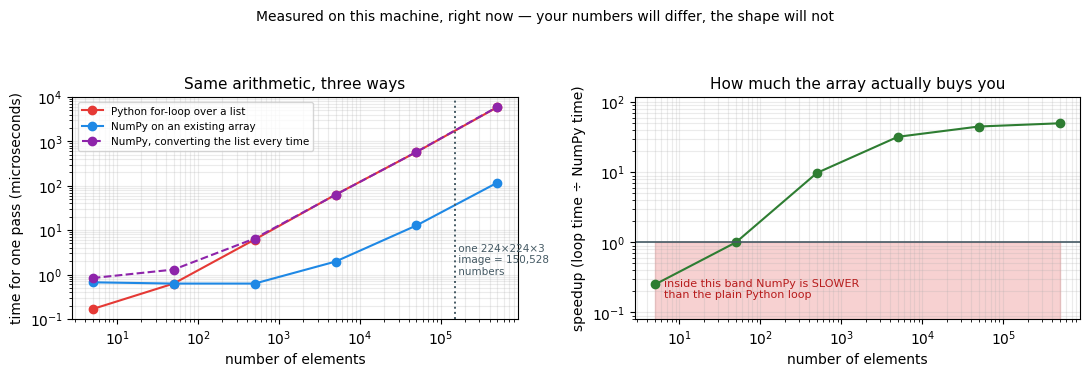

 elements   python loop   numpy array  numpy + convert   speedup
        5         0.2us         0.7us            0.8us     0.25x
       50         0.6us         0.6us            1.3us     1.00x
      500         6.1us         0.6us            6.5us     9.80x
    5,000        62.9us         2.0us           62.4us    32.13x
   50,000       574.6us        12.7us          578.9us    45.07x
  500,000      5898.9us       117.7us         5990.0us    50.11x

At 5 elements NumPy was 4.0x SLOWER than the plain loop.
At 500,000 elements NumPy was 50.1x faster.
Converting the list to an array every time costs 51x more than reusing the array at 500,000 elements — keep your data IN arrays.


In [8]:
# ── Measure the claim in the opening paragraph, do not just repeat it ────────
# WHAT: time the SAME arithmetic (sum of squares) three ways at six problem sizes:
#       a plain Python loop, NumPy on an array that already exists, and NumPy when the
#       list has to be converted every time. Nothing here is simulated — these are clocks.
# WHY:  "NumPy is faster" is a slogan until you see where it becomes true, and see the
#       size at which it is FALSE. Both facts are on the same picture.
import time

import matplotlib.pyplot as plt
import numpy as np


def best_of(fn, repeats=5):
    """Fastest of a few runs — the least noisy summary of how long an operation takes."""
    best = float('inf')
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        best = min(best, time.perf_counter() - t0)
    return best


sizes = [5, 50, 500, 5_000, 50_000, 500_000]     # 5 is the size of data_points above
loop_times, array_times, convert_times = [], [], []

for n in sizes:
    data = [i * 0.5 for i in range(n)]           # a plain Python list of n numbers
    arr = np.asarray(data)                       # the same numbers as a NumPy array

    def python_loop():                           # one interpreter step per element
        total = 0.0
        for x in data:
            total += x * x
        return total

    loop_times.append(best_of(python_loop))
    array_times.append(best_of(lambda: float((arr * arr).sum())))
    convert_times.append(best_of(lambda: float((np.asarray(data) ** 2).sum())))

speedup = [t_loop / t_arr for t_loop, t_arr in zip(loop_times, array_times)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

ax1.loglog(sizes, [t * 1e6 for t in loop_times], 'o-', color='#e53935', label='Python for-loop over a list')
ax1.loglog(sizes, [t * 1e6 for t in array_times], 'o-', color='#1e88e5', label='NumPy on an existing array')
ax1.loglog(sizes, [t * 1e6 for t in convert_times], 'o--', color='#8e24aa',
           label='NumPy, converting the list every time')
ax1.axvline(150_528, color='#455a64', linestyle=':', linewidth=1.4)
ax1.text(150_528, min(array_times) * 1e6 * 1.6, ' one 224×224×3\n image = 150,528\n numbers',
         fontsize=7.5, color='#455a64')
ax1.set_xlabel('number of elements')
ax1.set_ylabel('time for one pass (microseconds)')
ax1.set_title('Same arithmetic, three ways', fontsize=11)
ax1.grid(True, which='both', alpha=0.25)
ax1.legend(fontsize=7.5, loc='upper left')

ax2.loglog(sizes, speedup, 'o-', color='#2e7d32')
ax2.axhline(1.0, color='#455a64', linewidth=1.2)
ax2.fill_between(sizes, 0.05, 1, color='#ef9a9a', alpha=0.45)   # the "NumPy loses" zone
ax2.set_ylim(0.08, 120)
ax2.text(sizes[0] * 1.3, 0.16, 'inside this band NumPy is SLOWER\nthan the plain Python loop',
         fontsize=8, color='#b71c1c')
ax2.set_xlabel('number of elements')
ax2.set_ylabel('speedup (loop time ÷ NumPy time)')
ax2.set_title('How much the array actually buys you', fontsize=11)
ax2.grid(True, which='both', alpha=0.25)

fig.suptitle('Measured on this machine, right now — your numbers will differ, the shape will not',
             fontsize=10)
fig.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

print(f"{'elements':>9} {'python loop':>13} {'numpy array':>13} {'numpy + convert':>16} {'speedup':>9}")
for n, t_loop, t_arr, t_conv, s in zip(sizes, loop_times, array_times, convert_times, speedup):
    print(f"{n:>9,} {t_loop * 1e6:>11.1f}us {t_arr * 1e6:>11.1f}us {t_conv * 1e6:>14.1f}us {s:>8.2f}x")

# Two sentences that are computed from the measurement above, not typed by hand.
small, large = speedup[0], speedup[-1]
verdict_small = f"{1 / small:.1f}x SLOWER" if small < 1 else f"{small:.1f}x faster"
print(f"\nAt {sizes[0]} elements NumPy was {verdict_small} than the plain loop.")
print(f"At {sizes[-1]:,} elements NumPy was {large:.1f}x faster.")
print(f"Converting the list to an array every time costs "
      f"{convert_times[-1] / array_times[-1]:.0f}x more than reusing the array at "
      f"{sizes[-1]:,} elements — keep your data IN arrays.")


### 👁️ Read the two plots

Left: how long one pass of the same arithmetic takes, against the number of elements,
on log axes. Right: the same data as a single ratio — how many times faster the array
version was. Everything plotted here was measured by the cell you just ran.

**What the picture proves:**

- **At the size of the toy list at the top of this notebook, NumPy loses.** The red
  shaded region on the right is where the speedup is below 1×, and the first point
  sits in it — the printed line under the figure says by how much. Five elements do
  not pay for the cost of calling into a compiled library. This is why the loop and
  the array look interchangeable in a lesson, and are not interchangeable in a model.
- **The lines separate and never come back together.** By half a million elements the
  gap is the difference between a comfortable wait and an unusable program — and the
  vertical dotted line marks where a *single* 224×224 colour image already sits on
  that axis: 150,528 numbers, and a training batch is 32 of those.
- **The purple dashed line is the trap that catches beginners.** It is NumPy doing the
  identical arithmetic, but converting the Python list to an array on every call. It
  tracks the slow red loop almost exactly. The speed does not come from typing `np.`;
  it comes from the data *staying* in an array between operations.

The rule this supports is the one in "Where this breaks" at the end of the notebook:
vectorise the inner loop over data — do not reach for NumPy on five numbers, and do
not convert back and forth in the middle of a pipeline.


In [9]:
# File I/O in Python - Reading and writing files
import os
import tempfile

# Write inside a temporary folder, not the course folder, so running this lesson leaves nothing behind.
work_dir = tempfile.mkdtemp()
topics_path = os.path.join(work_dir, 'ai_topics.txt')

# Writing to a file
data = "AI, Machine Learning, Deep Learning, NLP"

with open(topics_path, 'w') as f:
    f.write(data)

print("✅ Data written to file")


✅ Data written to file


In [10]:
# Reading from a file
with open(topics_path, 'r') as f:
    content = f.read()

print(f"File content: {content}")
topics = content.split(', ')
print(f"\nTopics: {topics}")


File content: AI, Machine Learning, Deep Learning, NLP

Topics: ['AI', 'Machine Learning', 'Deep Learning', 'NLP']


## 💬 Discuss

You now have three containers: a **list**, a **dictionary**, and a **NumPy
array**. The choice is not cosmetic — it decides what you can compute and what
you can silently get wrong. Argue these:

1. The student record above was a dictionary (`name`, `age`, `grades`); the
   matrix was an array. **What breaks first** if you force each one into the
   other's shape? Name a concrete field that has no sensible home in an array.
2. We wrote `AI, Machine Learning, Deep Learning, NLP` to a file and parsed it by
   splitting on commas. Name a realistic value that would corrupt that file
   *without raising an error*, then decide: do you fix the parser, change the
   format, or refuse the data? Defend the choice to whoever sent you the file.
3. NumPy insists every element of an array has the same type — which rules out a
   table with a name column and an age column. Is that restriction a defect or a
   feature? Use the matrix multiplication above to support your answer.


## Summary

In this notebook, we reviewed:
- Python basics: lists, dictionaries, loops, conditionals
- NumPy for matrix operations
- File I/O operations
- Practical data processing for AI

**Next Steps:**
- Complete exercises in `exercises/` folder
- Practice with NumPy operations
- Work on file processing exercises

## ⚠️ Where this breaks

Everything in this notebook is correct, and none of it survives contact with a
real dataset unchanged.

- **Hand-rolled file parsing breaks on real text.** We used `content.split(', ')`.
  One value containing a comma, a quoted field, a Windows line ending or a
  non-UTF-8 byte destroys the result — and destroys it *silently*, handing you a
  wrong list instead of an error. **Use instead:** the `csv` module for delimited
  text, `json` for nested records, pandas (Course 05) for tables.
- **An array is a fixed-type, fixed-size block.** That is where the speed comes
  from and also where the limit is: mixed types, missing values (there is no
  `NaN` in an integer array) and growing row by row all fight the design. Named
  columns of different types are pandas' job, not NumPy's.
- **Our averages assumed clean data.** `sum(data) / len(data)` raises
  `ZeroDivisionError` on an empty list and `TypeError` if one grade is `None`.
  Five tidy numbers hid both failures; the Titanic file you meet in Unit 2 has
  177 missing ages out of 891.
- **Vectorization is not automatically faster.** For a handful of elements, or a
  loop whose body cannot be written as whole-array arithmetic, NumPy's per-call
  overhead makes it *slower* than plain Python. The rule is "vectorize the inner
  loop over data", not "never write a loop".


## 📚 References

1. Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). *Array programming with NumPy*. Nature, 585, 357–362. <https://arxiv.org/abs/2006.10256>
2. McKinney, W. (2010). *Data Structures for Statistical Computing in Python* (pandas). Proceedings of the 9th Python in Science Conference.
3. Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825–2830. <https://arxiv.org/abs/1201.0490>
4. Liang, H., Ma, X., Liu, Z., et al. (2025). *DataFlow: An LLM-Driven Framework for Unified Data Preparation and Workflow Automation in the Era of Data-Centric AI*. arXiv. <https://arxiv.org/abs/2512.16676>
5. Nguyen, C. V., Shen, X., Aponte, R., et al. (2024). *A Survey of Small Language Models*. arXiv. <https://arxiv.org/abs/2410.20011>